In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Настройки отображения pandas

In [8]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
pd.set_option('display.max_colwidth', 120)

# Настройки графиков

In [9]:
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12

# 1. Загрузка данных

In [14]:
DATA_PATH = 'netflix_titles.csv'

df = pd.read_csv(DATA_PATH)

print('Размер датасета:', df.shape)
display(df.head())

Размер датасета: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshab...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her si..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert ...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into ..."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student a..."


# 2. Первичный осмотр данных

In [16]:
print('\nИнформация о колонках:')
df.info()

print('\nНазвания колонок:')
print(df.columns.tolist())

print('\nКоличество строк и колонок:')
print(f'Строк: {df.shape[0]}')
print(f'Колонок: {df.shape[1]}')

print('\nПервые 5 строк:')
display(df.head())

print('\nСлучайные 5 строк:')
display(df.sample(5, random_state=42))


Информация о колонках:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Названия колонок:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Количество строк и колонок:
Строк: 8807
Колонок: 12

Первые 5 строк:

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshab...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her si..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert ...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into ..."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student a..."



Случайные 5 строк:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
4970,s4971,Movie,"Game Over, Man!",Kyle Newacheck,"Adam DeVine, Anders Holm, Blake Anderson, Utkarsh Ambudkar, Aya Cash, Neal McDonough, Daniel Stern, Jamie Demetriou,...",United States,"March 23, 2018",2018,TV-MA,102 min,"Action & Adventure, Comedies",Three buddies with big dreams go from underachieving slackers to badass warriors when their posh hotel is taken over...
3362,s3363,Movie,Arsenio Hall: Smart & Classy,Brian Volk-Weiss,Arsenio Hall,United States,"October 29, 2019",2019,TV-MA,63 min,Stand-Up Comedy,"In his first stand-up special, Arsenio Hall discusses getting older, the changing times and culture, social issues a..."
5494,s5495,TV Show,Kazoops!,NaN,"Reece Pockney, Scott Langley, Alex Babic, Gemma Harvey, Jessica Hann, Emma Tate",Australia,"May 5, 2017",2017,TV-Y,3 Seasons,Kids' TV,Music meets imagination in this inventive animated series about thinking outside the box and having fun.
1688,s1689,TV Show,We Are the Champions,NaN,NaN,United States,"November 17, 2020",2020,TV-MA,1 Season,"Docuseries, Reality TV","Explore an array of unique competitions, from the quirky to the bizarre, and meet their passionate communities in th..."
1349,s1350,TV Show,"Pablo Escobar, el patrón del mal",NaN,"Andrés Parra, Angie Cepeda, Cecilia Navia, Vicky Hernández, Christian Tappan, Rodolfo Silva, Tommy Vásquez, Toto Veg...",Colombia,"February 3, 2021",2012,TV-MA,1 Season,"Crime TV Shows, International TV Shows, Spanish-Language TV Shows","From his days as a petty thief to becoming head of a drug-trafficking empire, this riveting series charts the life o..."


# 3. Проверка дубликатов

In [17]:
print('Количество полных дубликатов:', df.duplicated().sum())
print('Количество дубликатов по show_id:', df['show_id'].duplicated().sum())
print('Количество дубликатов по title:', df['title'].duplicated().sum())

Количество полных дубликатов: 0
Количество дубликатов по show_id: 0
Количество дубликатов по title: 0


In [18]:
# Если есть полные дубликаты, удалим их
df = df.drop_duplicates()

# 4. Анализ пропусков


Пропуски по колонкам:


,missing_count,missing_percent
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


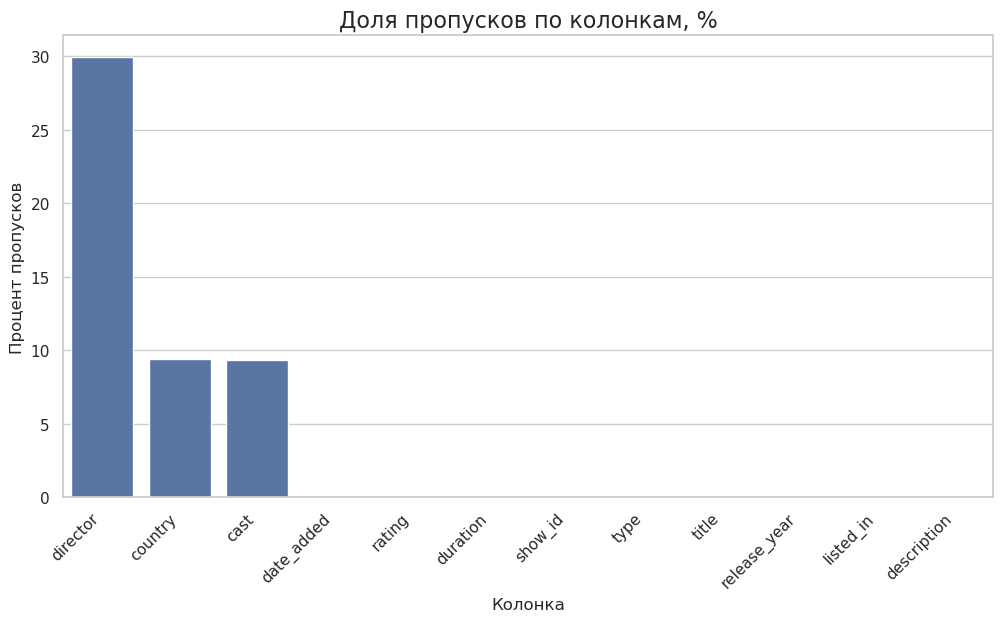

In [19]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_percent = (df.isnull().mean() * 100).sort_values(ascending=False)

missing_table = pd.DataFrame({
    'missing_count': missing,
    'missing_percent': missing_percent.round(2)
})

print('\nПропуски по колонкам:')
display(missing_table)

plt.figure(figsize=(12, 6))
sns.barplot(x=missing_table.index, y=missing_table['missing_percent'])
plt.xticks(rotation=45, ha='right')
plt.title('Доля пропусков по колонкам, %')
plt.ylabel('Процент пропусков')
plt.xlabel('Колонка')
plt.show()

# 5. Очистка данных

In [24]:
# Создадим копию для очищенных данных
df_clean = df.copy()

# Убираем лишние пробелы из названий колонок
df_clean.columns = df_clean.columns.str.strip()

# Заполняем пропуски в текстовых колонках значением Unknown
columns_to_fill_unknown = ['director', 'cast', 'country', 'rating']
for col in columns_to_fill_unknown:
    df_clean[col] = df_clean[col].fillna('Unknown')

# Преобразуем date_added в дату
df_clean['date_added'] = pd.to_datetime(df_clean['date_added'], errors='coerce')

# Создаем признаки из даты добавления
df_clean['year_added'] = df_clean['date_added'].dt.year
df_clean['month_added'] = df_clean['date_added'].dt.month
df_clean['month_name_added'] = df_clean['date_added'].dt.month_name()
df_clean['day_added'] = df_clean['date_added'].dt.day

# Обработка duration
df_clean['duration'] = df_clean['duration'].fillna('Unknown')
df_clean['duration_number'] = df_clean['duration'].str.extract(r'(\d+)').astype(float)

df_clean['duration_unit'] = df_clean['duration'].str.extract(r'([A-Za-z]+)')

def normalize_duration_unit(unit):
    if pd.isna(unit):
        return 'Unknown'
    unit = unit.lower()
    if 'min' in unit:
        return 'minutes'
    if 'season' in unit:
        return 'seasons'
    return unit

df_clean['duration_unit'] = df_clean['duration_unit'].apply(normalize_duration_unit)

print('\nПосле очистки:')
display(df_clean.head())
print(df_clean.info())


После очистки:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,month_name_added,day_added,duration_number,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to...",2021.0,9.0,September,25.0,90.0,minutes
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshab...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her si...",2021.0,9.0,September,24.0,2.0,seasons
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert ...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into ...",2021.0,9.0,September,24.0,1.0,seasons
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans...",2021.0,9.0,September,24.0,1.0,seasons
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student a...",2021.0,9.0,September,24.0,2.0,seasons


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   show_id           8807 non-null   object        
 1   type              8807 non-null   object        
 2   title             8807 non-null   object        
 3   director          8807 non-null   object        
 4   cast              8807 non-null   object        
 5   country           8807 non-null   object        
 6   date_added        8709 non-null   datetime64[ns]
 7   release_year      8807 non-null   int64         
 8   rating            8807 non-null   object        
 9   duration          8807 non-null   object        
 10  listed_in         8807 non-null   object        
 11  description       8807 non-null   object        
 12  year_added        8709 non-null   float64       
 13  month_added       8709 non-null   float64       
 14  month_name_added  8709 n

# 6. Общая статистика

In [25]:
print('Количество уникальных show_id:', df_clean['show_id'].nunique())
print('Количество уникальных названий:', df_clean['title'].nunique())
print('Минимальный год выпуска:', df_clean['release_year'].min())
print('Максимальный год выпуска:', df_clean['release_year'].max())
print('Минимальная дата добавления:', df_clean['date_added'].min())
print('Максимальная дата добавления:', df_clean['date_added'].max())

print('\nРаспределение по типам контента:')
display(df_clean['type'].value_counts())

Количество уникальных show_id: 8807
Количество уникальных названий: 8807
Минимальный год выпуска: 1925
Максимальный год выпуска: 2021
Минимальная дата добавления: 2008-01-01 00:00:00
Максимальная дата добавления: 2021-09-25 00:00:00

Распределение по типам контента:


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

# 7. Анализ Movie vs TV Show

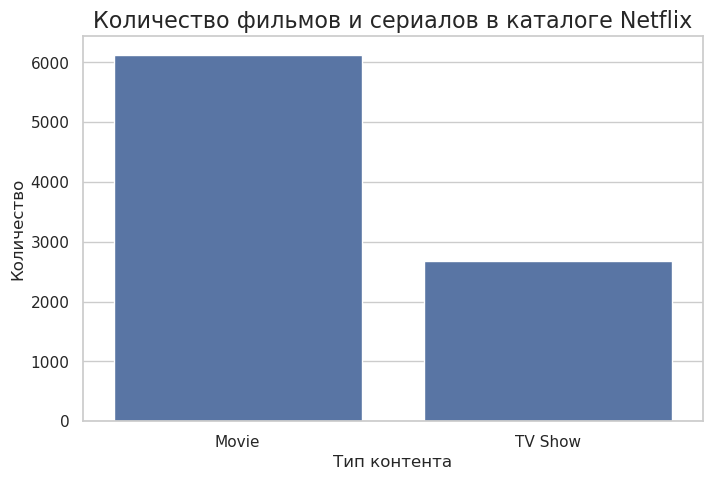

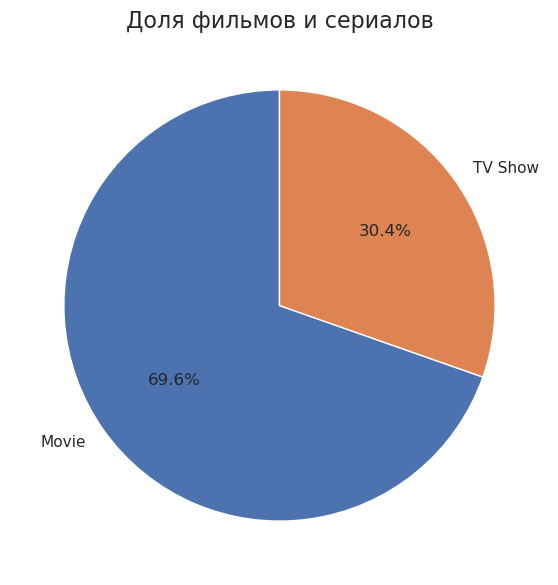


Вывод:
В каталоге больше фильмов, чем сериалов.


In [26]:
type_counts = df_clean['type'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=type_counts.index, y=type_counts.values)
plt.title('Количество фильмов и сериалов в каталоге Netflix')
plt.xlabel('Тип контента')
plt.ylabel('Количество')
plt.show()

plt.figure(figsize=(7, 7))
plt.pie(type_counts.values, labels=type_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Доля фильмов и сериалов')
plt.show()

print('\nВывод:')
if type_counts.get('Movie', 0) > type_counts.get('TV Show', 0):
    print('В каталоге больше фильмов, чем сериалов.')
else:
    print('В каталоге больше сериалов, чем фильмов.')


# 8. Анализ годов выпуска

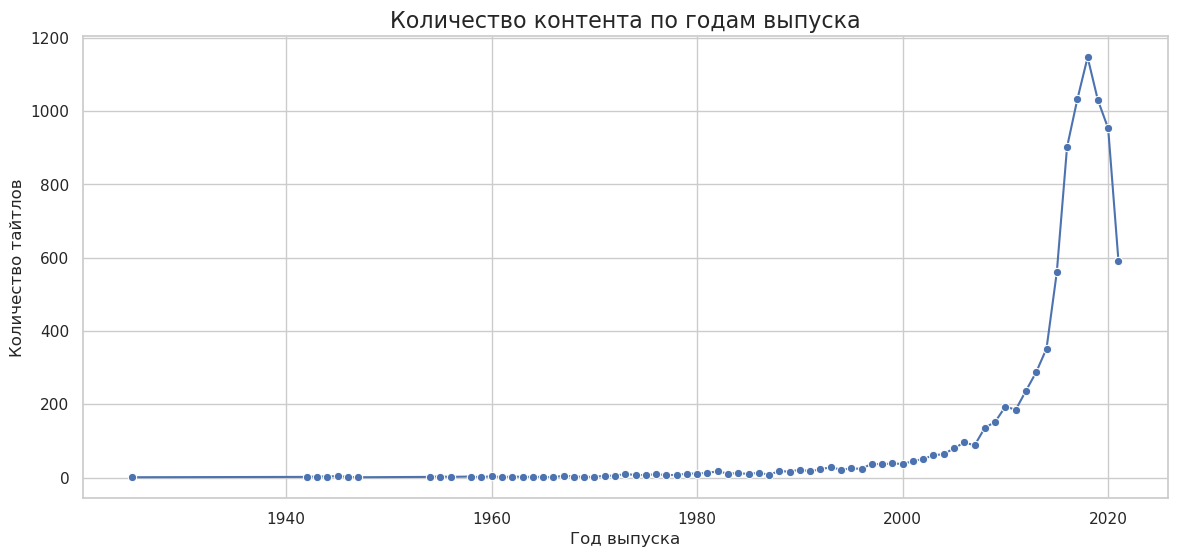

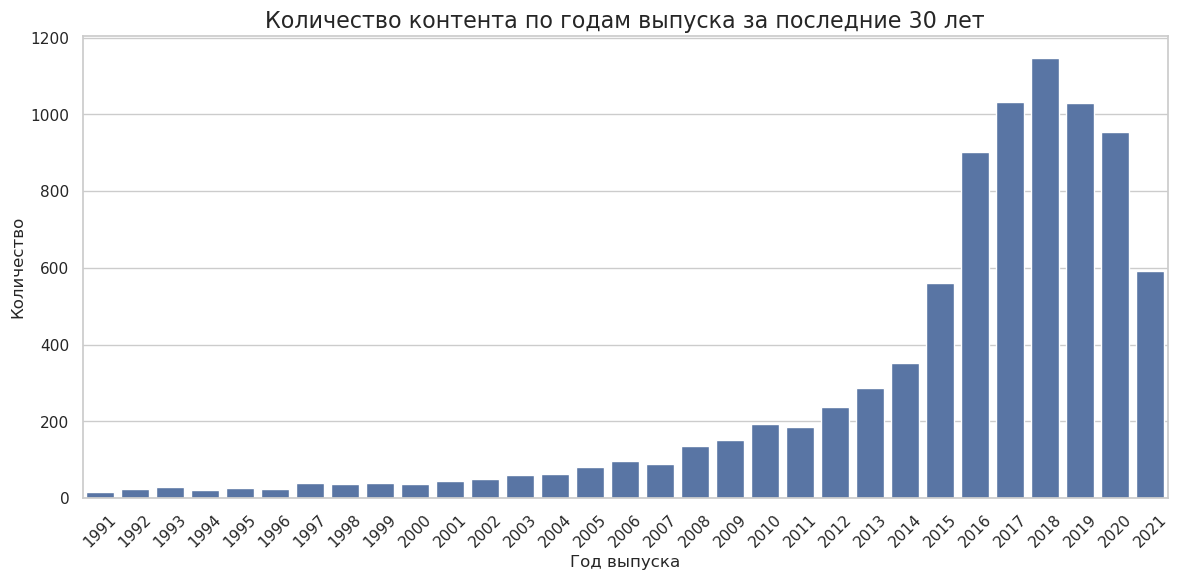


Топ-10 годов по количеству контента:


release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
2021     592
2015     560
2014     352
2013     288
2012     237
Name: count, dtype: int64

In [27]:
release_counts = df_clean['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))
sns.lineplot(x=release_counts.index, y=release_counts.values, marker='o')
plt.title('Количество контента по годам выпуска')
plt.xlabel('Год выпуска')
plt.ylabel('Количество тайтлов')
plt.show()

# Последние 30 лет для более читаемого графика
recent_years = df_clean[df_clean['release_year'] >= df_clean['release_year'].max() - 30]
recent_release_counts = recent_years['release_year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))
sns.barplot(x=recent_release_counts.index, y=recent_release_counts.values)
plt.xticks(rotation=45)
plt.title('Количество контента по годам выпуска за последние 30 лет')
plt.xlabel('Год выпуска')
plt.ylabel('Количество')
plt.show()

print('\nТоп-10 годов по количеству контента:')
display(df_clean['release_year'].value_counts().head(10))

# 9. Анализ даты добавления на Netflix

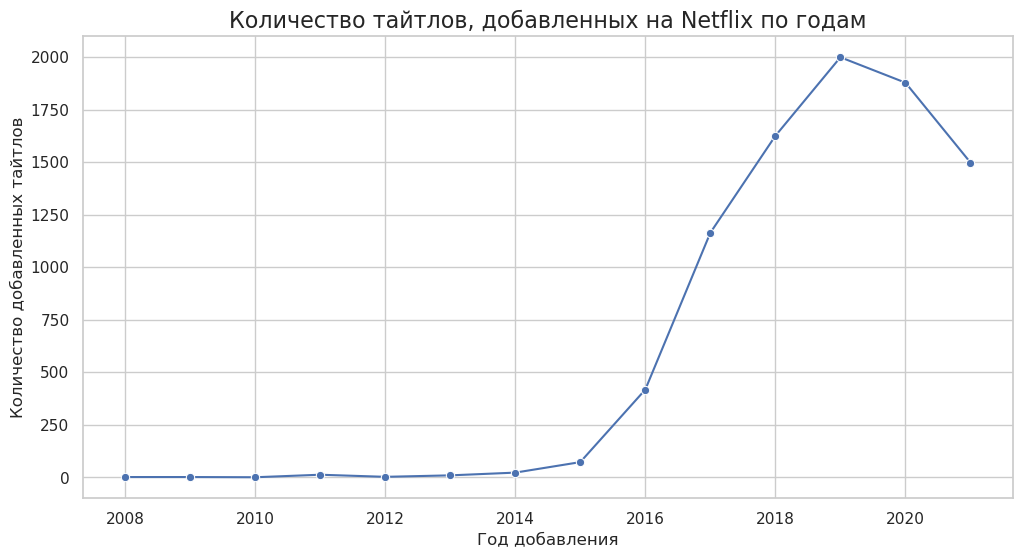

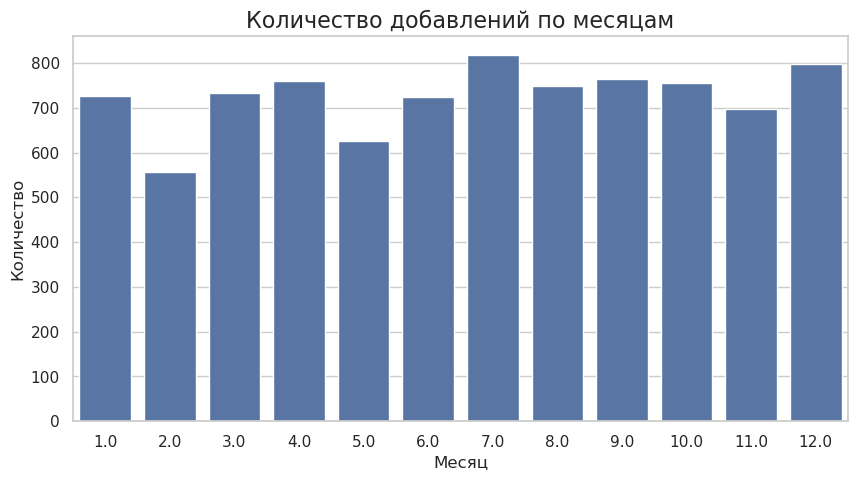


Топ годов добавления:


year_added
2019.0    1999
2020.0    1878
2018.0    1625
2021.0    1498
2017.0    1164
2016.0     418
2015.0      73
2014.0      23
2011.0      13
2013.0      10
Name: count, dtype: int64

In [28]:

year_added_counts = df_clean['year_added'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
sns.lineplot(x=year_added_counts.index, y=year_added_counts.values, marker='o')
plt.title('Количество тайтлов, добавленных на Netflix по годам')
plt.xlabel('Год добавления')
plt.ylabel('Количество добавленных тайтлов')
plt.show()

month_counts = df_clean['month_added'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=month_counts.index, y=month_counts.values)
plt.title('Количество добавлений по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество')
plt.show()

print('\nТоп годов добавления:')
display(df_clean['year_added'].value_counts().head(10))

# 10. Сравнение Movies и TV Shows по годам добавления

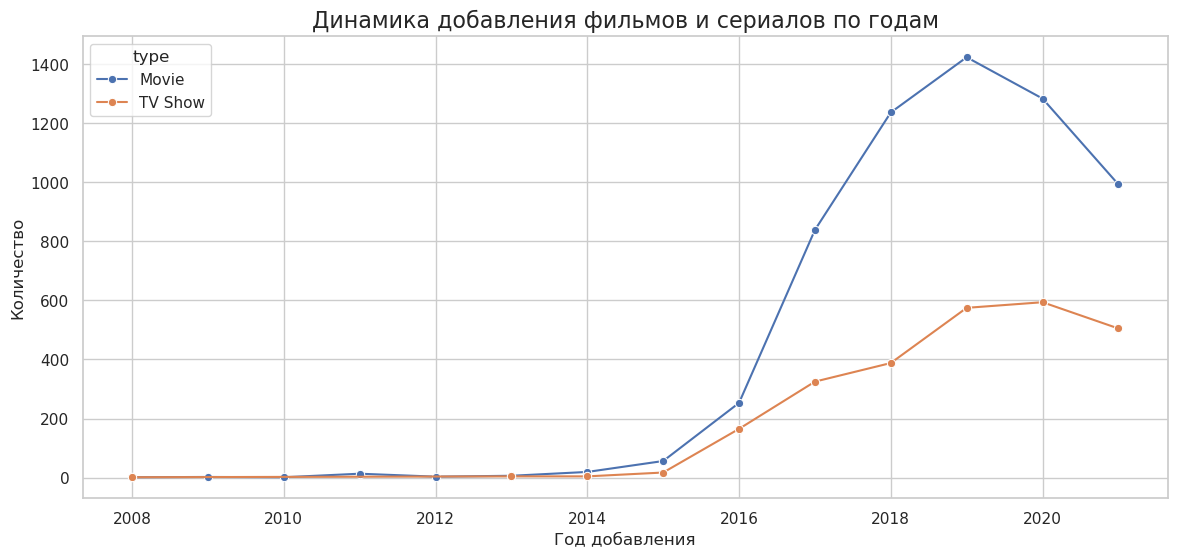

In [29]:
content_by_year_type = df_clean.groupby(['year_added', 'type']).size().reset_index(name='count')

plt.figure(figsize=(14, 6))
sns.lineplot(data=content_by_year_type, x='year_added', y='count', hue='type', marker='o')
plt.title('Динамика добавления фильмов и сериалов по годам')
plt.xlabel('Год добавления')
plt.ylabel('Количество')
plt.show()


# 11. Анализ рейтингов

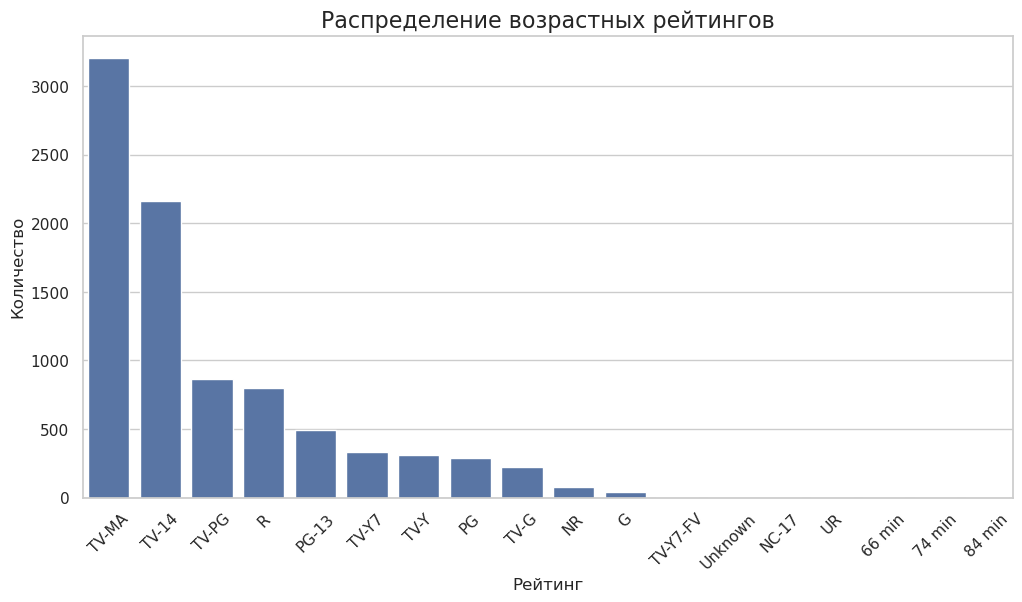


Топ рейтингов:


rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
Name: count, dtype: int64

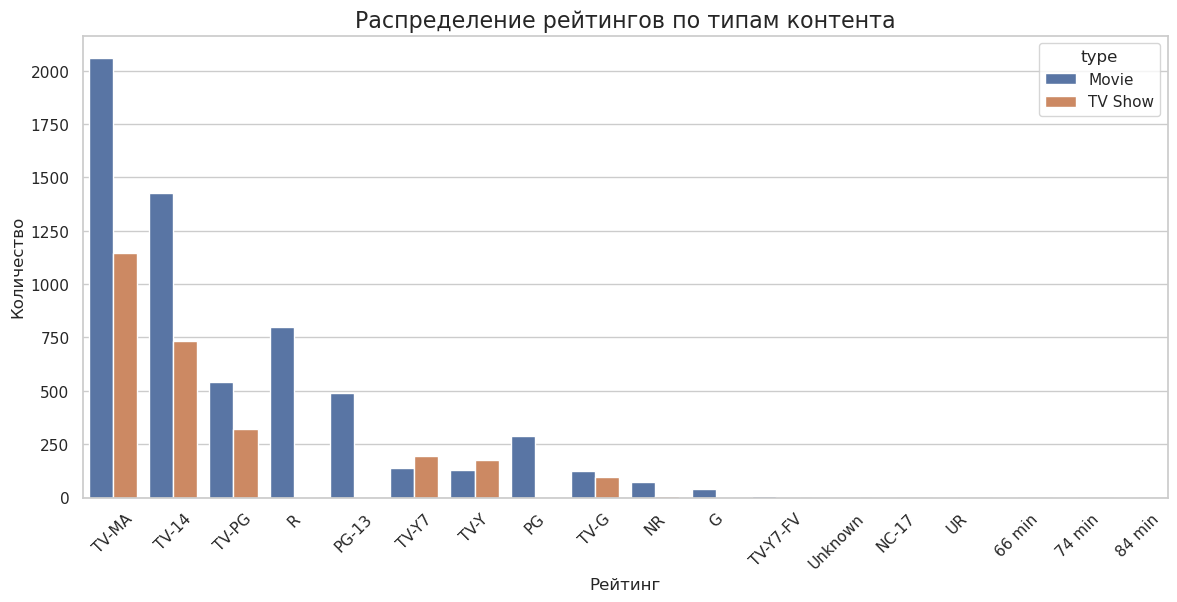

In [31]:
rating_counts = df_clean['rating'].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=rating_counts.index, y=rating_counts.values)
plt.xticks(rotation=45)
plt.title('Распределение возрастных рейтингов')
plt.xlabel('Рейтинг')
plt.ylabel('Количество')
plt.show()

print('\nТоп рейтингов:')
display(rating_counts.head(15))

# Рейтинги отдельно для фильмов и сериалов
plt.figure(figsize=(14, 6))
sns.countplot(data=df_clean, x='rating', hue='type', order=rating_counts.index)
plt.xticks(rotation=45)
plt.title('Распределение рейтингов по типам контента')
plt.xlabel('Рейтинг')
plt.ylabel('Количество')
plt.show()


# 12. Анализ стран

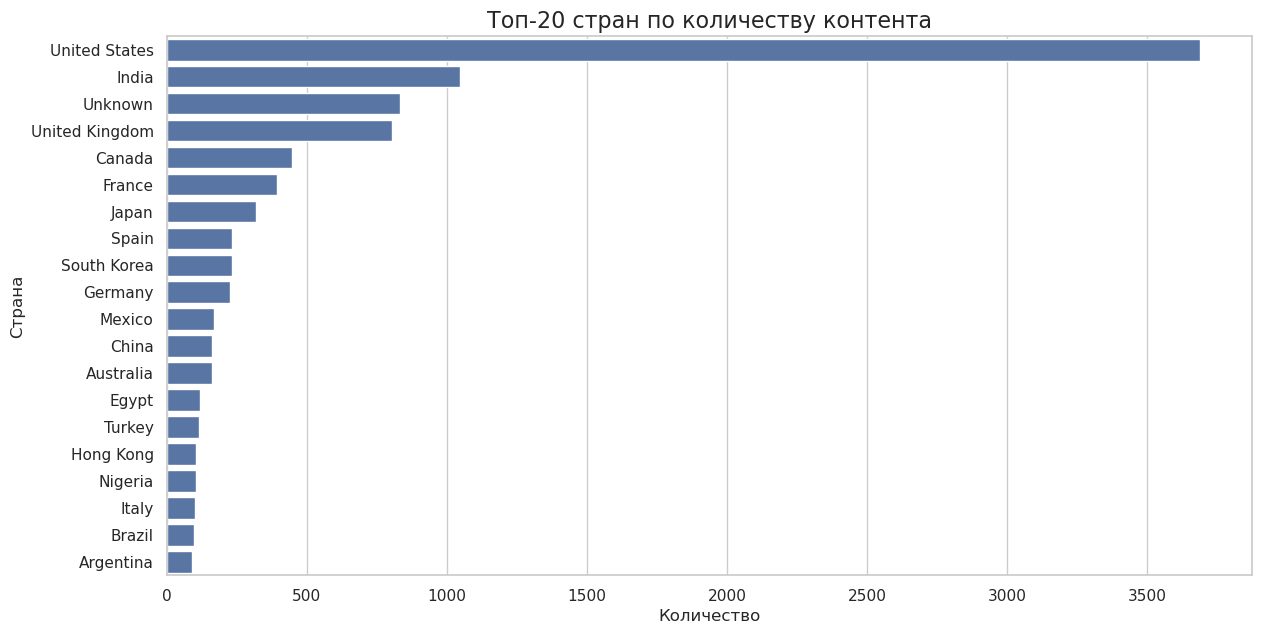


Топ-20 стран:


country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
China              162
Australia          160
Egypt              117
Turkey             113
Hong Kong          105
Nigeria            103
Italy              100
Brazil              97
Argentina           91
Name: count, dtype: int64

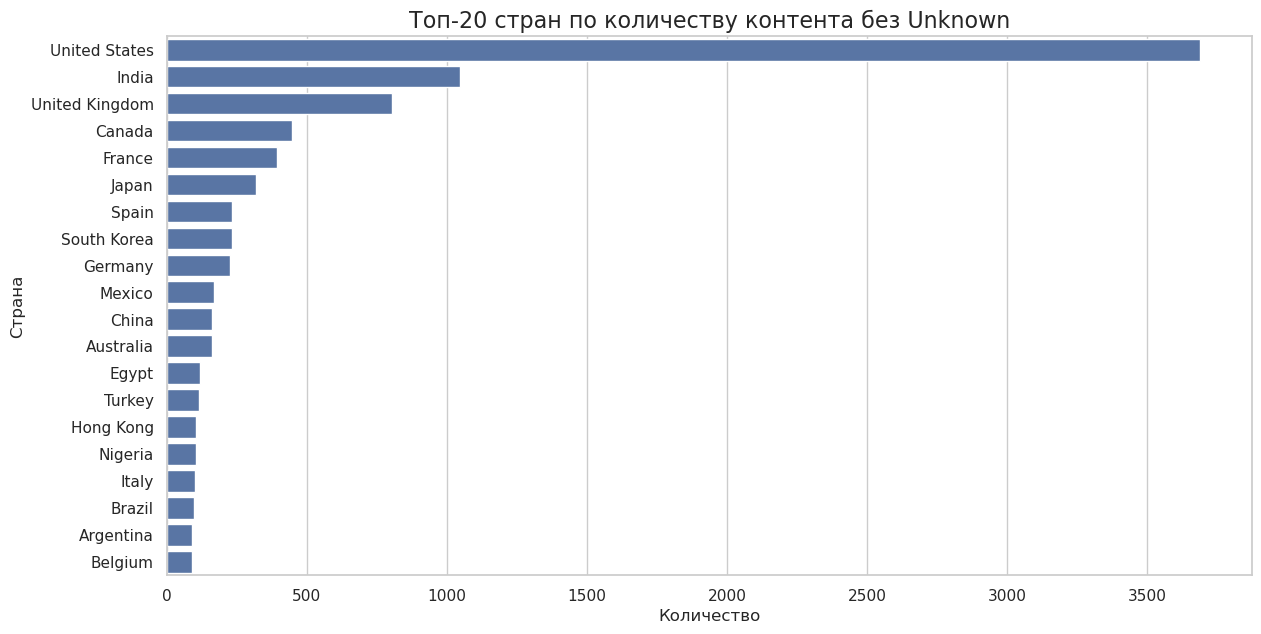

In [32]:
country_df = df_clean[['show_id', 'title', 'type', 'country']].copy()
country_df['country'] = country_df['country'].str.split(', ')
country_df = country_df.explode('country')
country_df['country'] = country_df['country'].fillna('Unknown')

country_counts = country_df['country'].value_counts().head(20)

plt.figure(figsize=(14, 7))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title('Топ-20 стран по количеству контента')
plt.xlabel('Количество')
plt.ylabel('Страна')
plt.show()

print('\nТоп-20 стран:')
display(country_counts)

country_counts_without_unknown = country_df[country_df['country'] != 'Unknown']['country'].value_counts().head(20)

plt.figure(figsize=(14, 7))
sns.barplot(x=country_counts_without_unknown.values, y=country_counts_without_unknown.index)
plt.title('Топ-20 стран по количеству контента без Unknown')
plt.xlabel('Количество')
plt.ylabel('Страна')
plt.show()

# 13. Анализ жанров / категорий

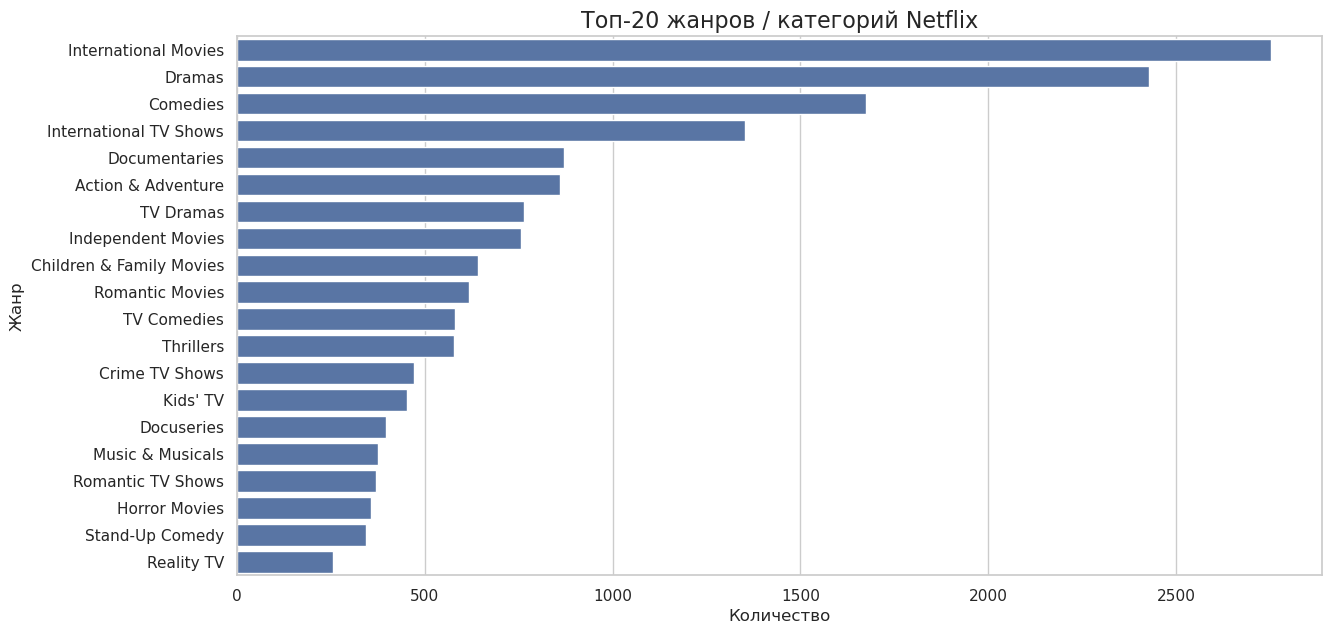


Топ-20 жанров:


genre
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
TV Comedies                  581
Thrillers                    577
Crime TV Shows               470
Kids' TV                     451
Docuseries                   395
Music & Musicals             375
Romantic TV Shows            370
Horror Movies                357
Stand-Up Comedy              343
Reality TV                   255
Name: count, dtype: int64

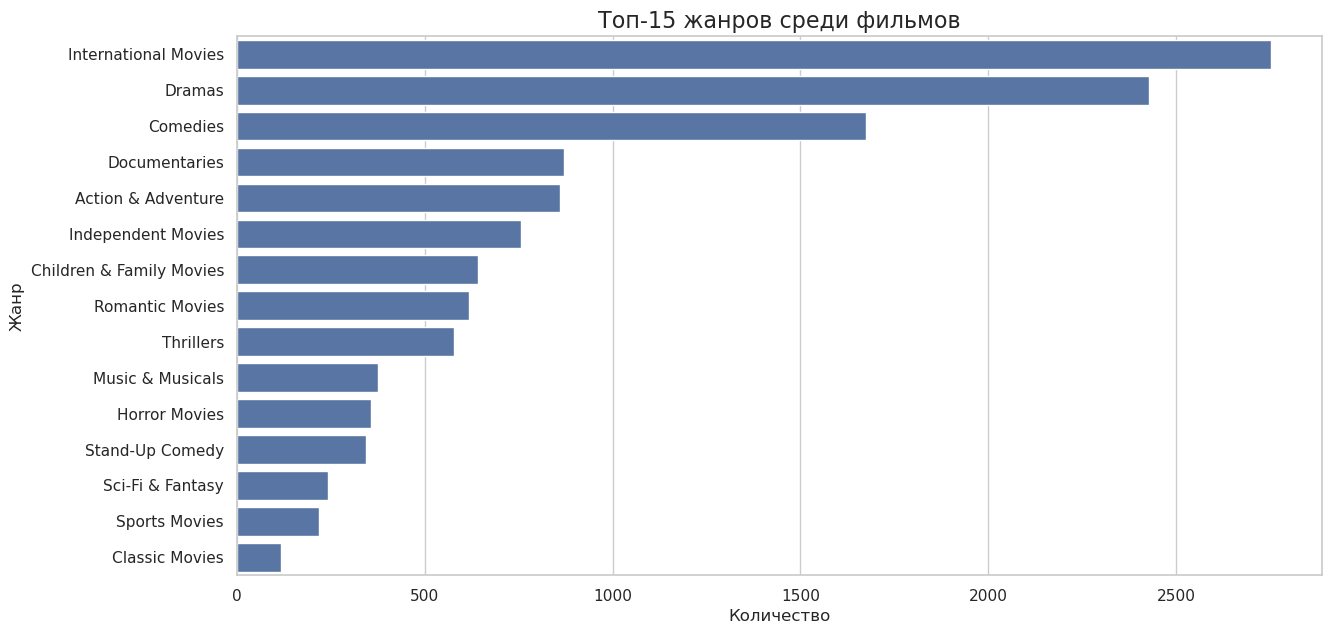

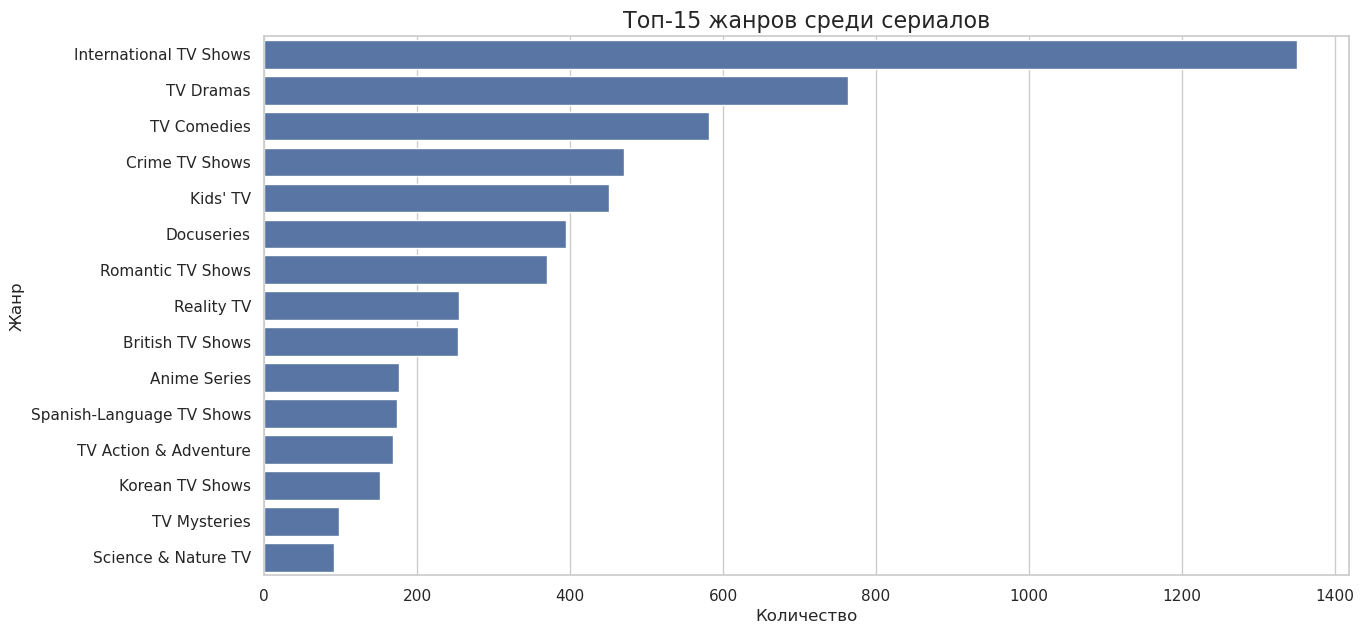

In [33]:
genre_df = df_clean[['show_id', 'title', 'type', 'listed_in', 'release_year', 'year_added']].copy()
genre_df['genre'] = genre_df['listed_in'].str.split(', ')
genre_df = genre_df.explode('genre')

genre_counts = genre_df['genre'].value_counts().head(20)

plt.figure(figsize=(14, 7))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title('Топ-20 жанров / категорий Netflix')
plt.xlabel('Количество')
plt.ylabel('Жанр')
plt.show()

print('\nТоп-20 жанров:')
display(genre_counts)

# Жанры отдельно для фильмов и сериалов
movie_genres = genre_df[genre_df['type'] == 'Movie']['genre'].value_counts().head(15)
tv_genres = genre_df[genre_df['type'] == 'TV Show']['genre'].value_counts().head(15)

plt.figure(figsize=(14, 7))
sns.barplot(x=movie_genres.values, y=movie_genres.index)
plt.title('Топ-15 жанров среди фильмов')
plt.xlabel('Количество')
plt.ylabel('Жанр')
plt.show()

plt.figure(figsize=(14, 7))
sns.barplot(x=tv_genres.values, y=tv_genres.index)
plt.title('Топ-15 жанров среди сериалов')
plt.xlabel('Количество')
plt.ylabel('Жанр')
plt.show()

# 14. Анализ длительности фильмов


Статистика длительности фильмов:


count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_number, dtype: float64

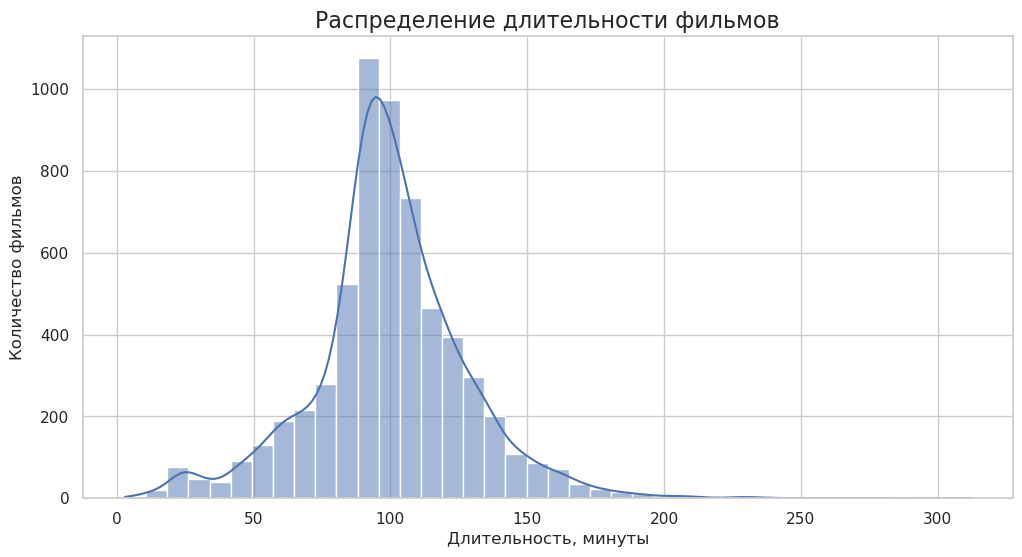

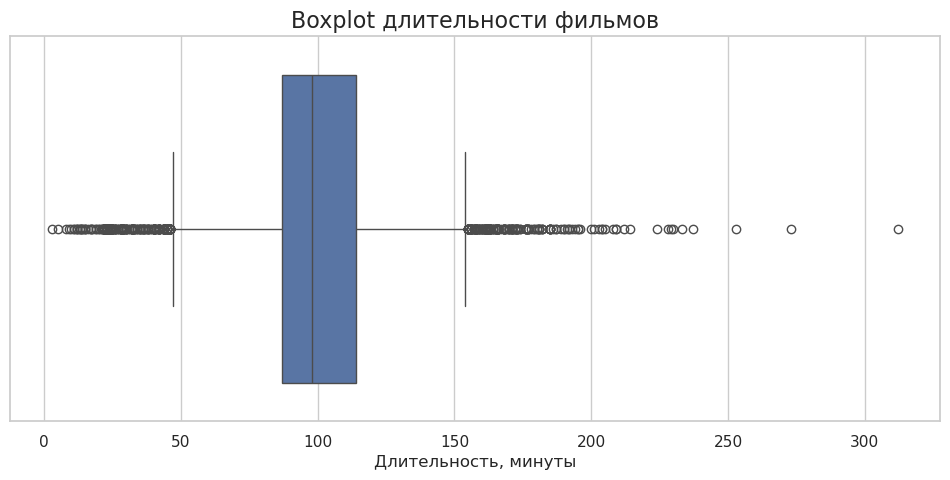


Самые длинные фильмы:


,title,release_year,duration,listed_in
4253,Black Mirror: Bandersnatch,2018,312 min,"Dramas, International Movies, Sci-Fi & Fantasy"
717,Headspace: Unwind Your Mind,2021,273 min,Documentaries
2491,The School of Mischief,1973,253 min,"Comedies, Dramas, International Movies"
2487,No Longer kids,1979,237 min,"Comedies, Dramas, International Movies"
2484,Lock Your Girls In,1982,233 min,"Comedies, International Movies, Romantic Movies"
2488,Raya and Sakina,1984,230 min,"Comedies, Dramas, International Movies"
166,Once Upon a Time in America,1984,229 min,"Classic Movies, Dramas"
7932,Sangam,1964,228 min,"Classic Movies, Dramas, International Movies"
1019,Lagaan,2001,224 min,"Dramas, International Movies, Music & Musicals"
4573,Jodhaa Akbar,2008,214 min,"Action & Adventure, Dramas, International Movies"



Самые короткие фильмы:


,title,release_year,duration,listed_in
3777,Silent,2014,3 min,"Children & Family Movies, Sci-Fi & Fantasy"
2713,Sol Levante,2020,5 min,"Action & Adventure, Anime Features, International Movies"
1484,Cops and Robbers,2020,8 min,Dramas
1557,Canvas,2020,9 min,"Children & Family Movies, Dramas"
3535,American Factory: A Conversation with the Obamas,2019,10 min,Documentaries
2858,Calico Critters: Everyone's Big Dream Flying in the Sky,2019,11 min,Children & Family Movies
6405,Calico Critters: A Town of Dreams,2017,11 min,Children & Family Movies
3775,Cosmos Laundromat: First Cycle,2015,12 min,"Dramas, International Movies, Sci-Fi & Fantasy"
4707,Zion,2018,12 min,"Documentaries, Sports Movies"
695,Besieged Bread,2015,12 min,"Dramas, International Movies"


In [34]:

movies = df_clean[df_clean['type'] == 'Movie'].copy()
tv_shows = df_clean[df_clean['type'] == 'TV Show'].copy()

movie_durations = movies[movies['duration_unit'] == 'minutes']['duration_number'].dropna()

print('\nСтатистика длительности фильмов:')
display(movie_durations.describe())

plt.figure(figsize=(12, 6))
sns.histplot(movie_durations, bins=40, kde=True)
plt.title('Распределение длительности фильмов')
plt.xlabel('Длительность, минуты')
plt.ylabel('Количество фильмов')
plt.show()

plt.figure(figsize=(12, 5))
sns.boxplot(x=movie_durations)
plt.title('Boxplot длительности фильмов')
plt.xlabel('Длительность, минуты')
plt.show()

print('\nСамые длинные фильмы:')
display(movies.sort_values('duration_number', ascending=False)[['title', 'release_year', 'duration', 'listed_in']].head(10))

print('\nСамые короткие фильмы:')
display(movies[movies['duration_number'].notna()].sort_values('duration_number')[['title', 'release_year', 'duration', 'listed_in']].head(10))

# 15. Анализ количества сезонов сериалов


Статистика количества сезонов сериалов:


count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_number, dtype: float64

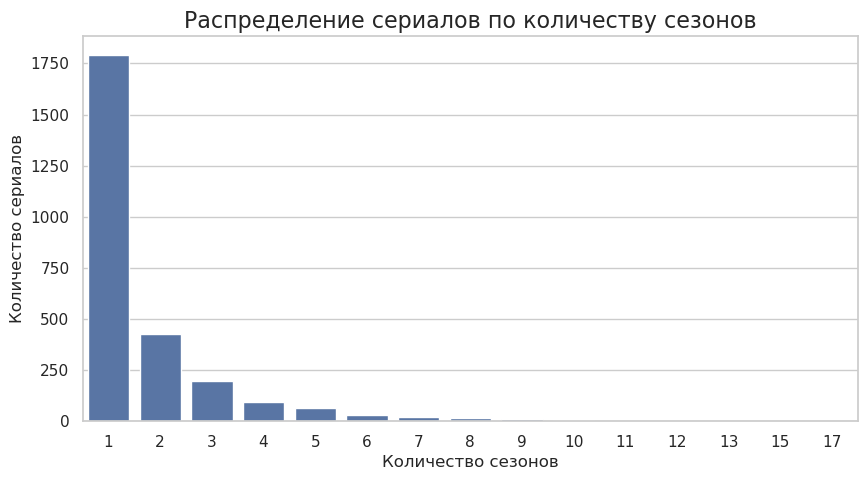


Сериалы с наибольшим количеством сезонов:


,title,release_year,duration,listed_in
548,Grey's Anatomy,2020,17 Seasons,"Romantic TV Shows, TV Dramas"
4798,NCIS,2017,15 Seasons,"Crime TV Shows, TV Dramas, TV Mysteries"
2423,Supernatural,2019,15 Seasons,"Classic & Cult TV, TV Action & Adventure, TV Horror"
1354,Heartland,2019,13 Seasons,TV Dramas
4220,COMEDIANS of the world,2019,13 Seasons,"Stand-Up Comedy & Talk Shows, TV Comedies"
7847,Red vs. Blue,2015,13 Seasons,"TV Action & Adventure, TV Comedies, TV Sci-Fi & Fantasy"
4964,Trailer Park Boys,2018,12 Seasons,"Classic & Cult TV, Crime TV Shows, International TV Shows"
5412,Criminal Minds,2017,12 Seasons,"Crime TV Shows, TV Dramas, TV Mysteries"
6795,Frasier,2003,11 Seasons,"Classic & Cult TV, TV Comedies"
6456,Cheers,1992,11 Seasons,"Classic & Cult TV, TV Comedies"


In [35]:
tv_seasons = tv_shows[tv_shows['duration_unit'] == 'seasons']['duration_number'].dropna()

print('\nСтатистика количества сезонов сериалов:')
display(tv_seasons.describe())

plt.figure(figsize=(10, 5))
sns.countplot(x=tv_seasons.astype(int))
plt.title('Распределение сериалов по количеству сезонов')
plt.xlabel('Количество сезонов')
plt.ylabel('Количество сериалов')
plt.show()

print('\nСериалы с наибольшим количеством сезонов:')
display(tv_shows.sort_values('duration_number', ascending=False)[['title', 'release_year', 'duration', 'listed_in']].head(10))

# 16. Анализ режиссёров

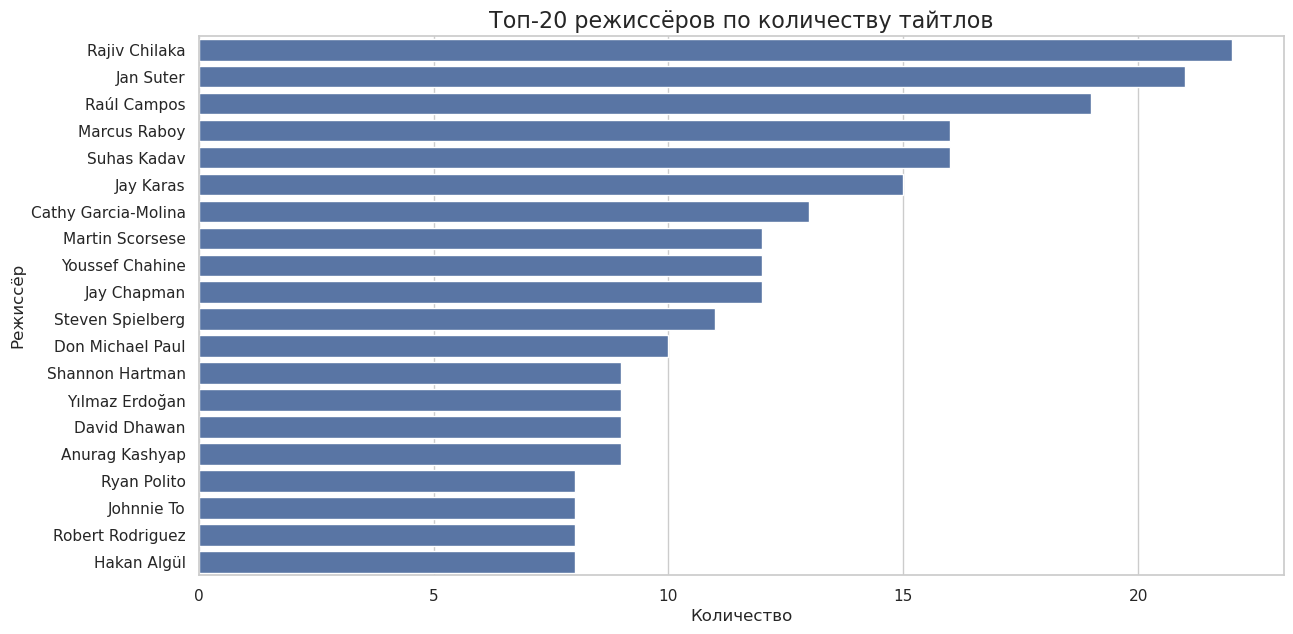


Топ-20 режиссёров:


director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Marcus Raboy           16
Suhas Kadav            16
Jay Karas              15
Cathy Garcia-Molina    13
Martin Scorsese        12
Youssef Chahine        12
Jay Chapman            12
Steven Spielberg       11
Don Michael Paul       10
Shannon Hartman         9
Yılmaz Erdoğan          9
David Dhawan            9
Anurag Kashyap          9
Ryan Polito             8
Johnnie To              8
Robert Rodriguez        8
Hakan Algül             8
Name: count, dtype: int64

In [36]:
director_df = df_clean[['show_id', 'title', 'type', 'director']].copy()
director_df = director_df[director_df['director'] != 'Unknown']
director_df['director'] = director_df['director'].str.split(', ')
director_df = director_df.explode('director')

top_directors = director_df['director'].value_counts().head(20)

plt.figure(figsize=(14, 7))
sns.barplot(x=top_directors.values, y=top_directors.index)
plt.title('Топ-20 режиссёров по количеству тайтлов')
plt.xlabel('Количество')
plt.ylabel('Режиссёр')
plt.show()

print('\nТоп-20 режиссёров:')
display(top_directors)

# 17. Анализ актёров

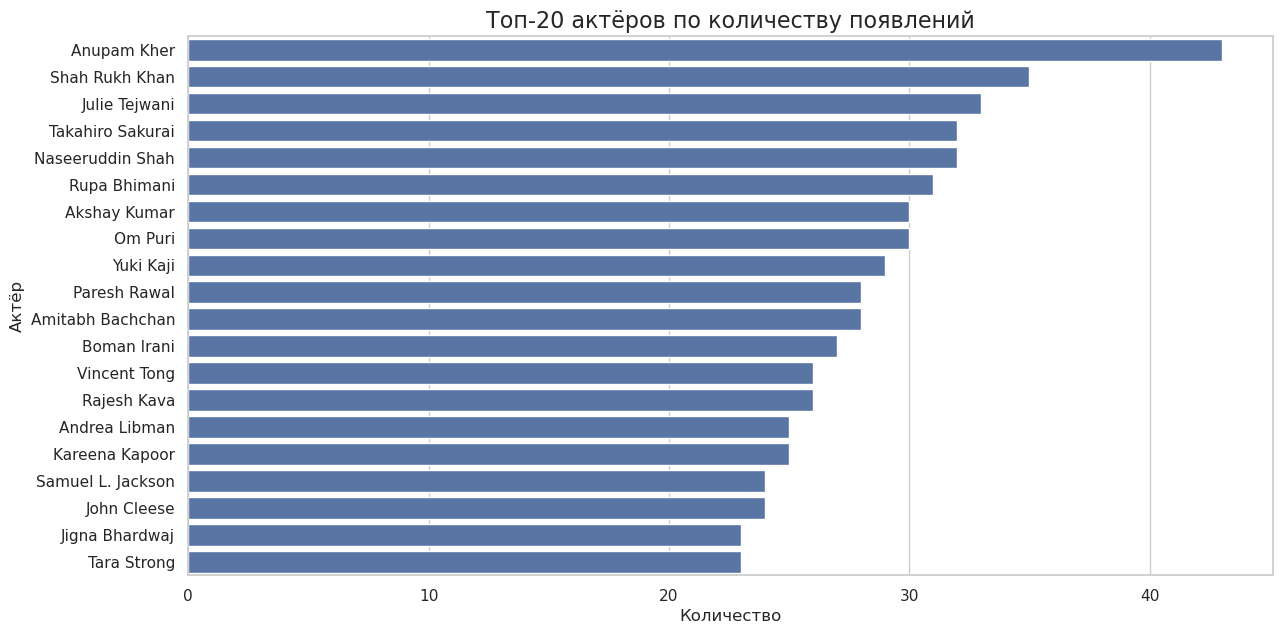


Топ-20 актёров:


actor
Anupam Kher          43
Shah Rukh Khan       35
Julie Tejwani        33
Takahiro Sakurai     32
Naseeruddin Shah     32
Rupa Bhimani         31
Akshay Kumar         30
Om Puri              30
Yuki Kaji            29
Paresh Rawal         28
Amitabh Bachchan     28
Boman Irani          27
Vincent Tong         26
Rajesh Kava          26
Andrea Libman        25
Kareena Kapoor       25
Samuel L. Jackson    24
John Cleese          24
Jigna Bhardwaj       23
Tara Strong          23
Name: count, dtype: int64

In [37]:
cast_df = df_clean[['show_id', 'title', 'type', 'cast']].copy()
cast_df = cast_df[cast_df['cast'] != 'Unknown']
cast_df['actor'] = cast_df['cast'].str.split(', ')
cast_df = cast_df.explode('actor')

top_actors = cast_df['actor'].value_counts().head(20)

plt.figure(figsize=(14, 7))
sns.barplot(x=top_actors.values, y=top_actors.index)
plt.title('Топ-20 актёров по количеству появлений')
plt.xlabel('Количество')
plt.ylabel('Актёр')
plt.show()

print('\nТоп-20 актёров:')
display(top_actors)

# 18. Анализ связки страна + тип контента

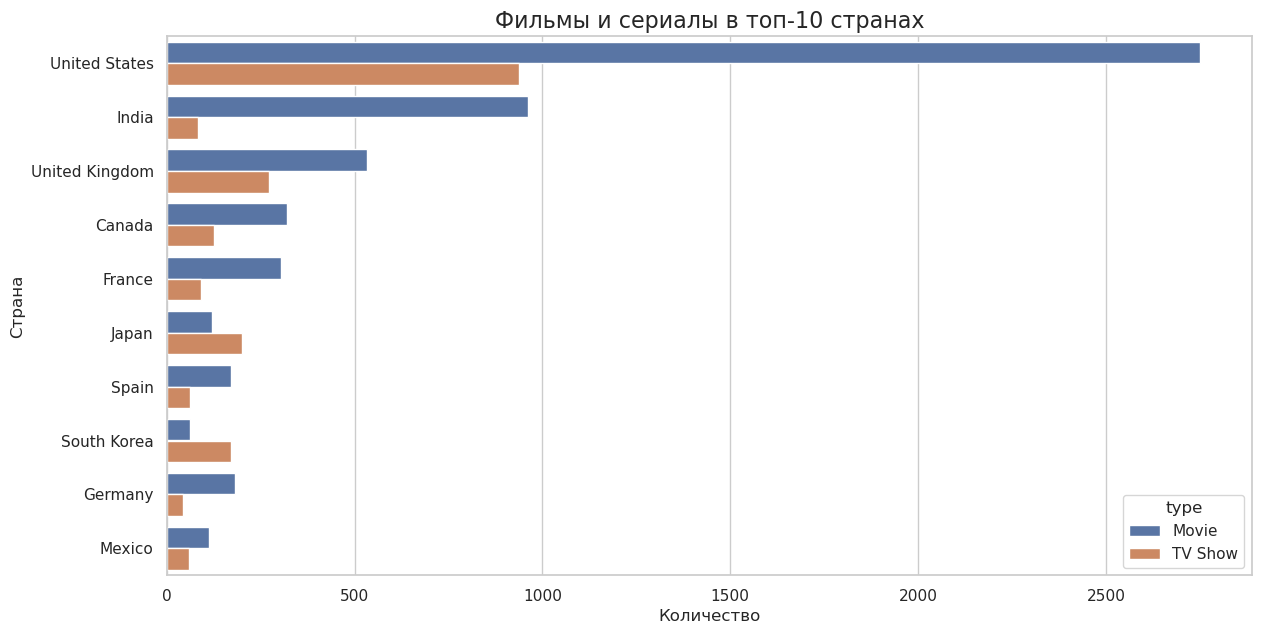


Таблица: страна x тип контента


type,Movie,TV Show
country,,
Canada,319,126
France,303,90
Germany,182,44
India,962,84
Japan,119,199
Mexico,111,58
South Korea,61,170
Spain,171,61
United Kingdom,532,272


In [39]:
top_10_countries = country_counts_without_unknown.head(10).index
country_type_df = country_df[country_df['country'].isin(top_10_countries)]

plt.figure(figsize=(14, 7))
sns.countplot(data=country_type_df, y='country', hue='type', order=top_10_countries)
plt.title('Фильмы и сериалы в топ-10 странах')
plt.xlabel('Количество')
plt.ylabel('Страна')
plt.show()

country_type_pivot = country_type_df.pivot_table(
    index='country',
    columns='type',
    values='show_id',
    aggfunc='count',
    fill_value=0
)

print('\nТаблица: страна x тип контента')
display(country_type_pivot)

# 19. Анализ жанров по годам

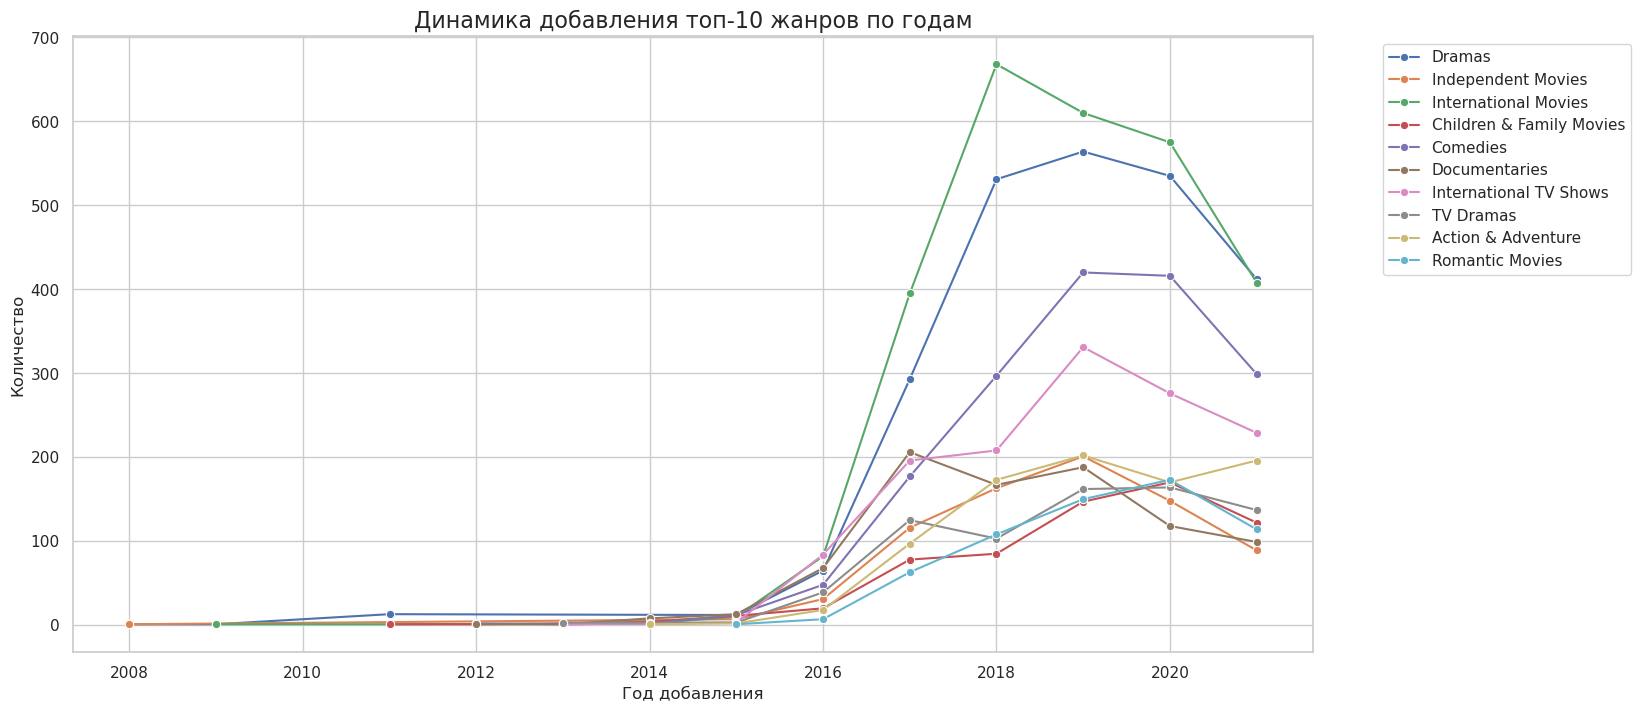

In [40]:
top_10_genres = genre_df['genre'].value_counts().head(10).index
popular_genres_by_year = genre_df[genre_df['genre'].isin(top_10_genres)]
popular_genres_by_year = popular_genres_by_year.dropna(subset=['year_added'])

genre_year_counts = popular_genres_by_year.groupby(['year_added', 'genre']).size().reset_index(name='count')

plt.figure(figsize=(16, 8))
sns.lineplot(data=genre_year_counts, x='year_added', y='count', hue='genre', marker='o')
plt.title('Динамика добавления топ-10 жанров по годам')
plt.xlabel('Год добавления')
plt.ylabel('Количество')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# 20. Тепловая карта: месяцы и годы добавления

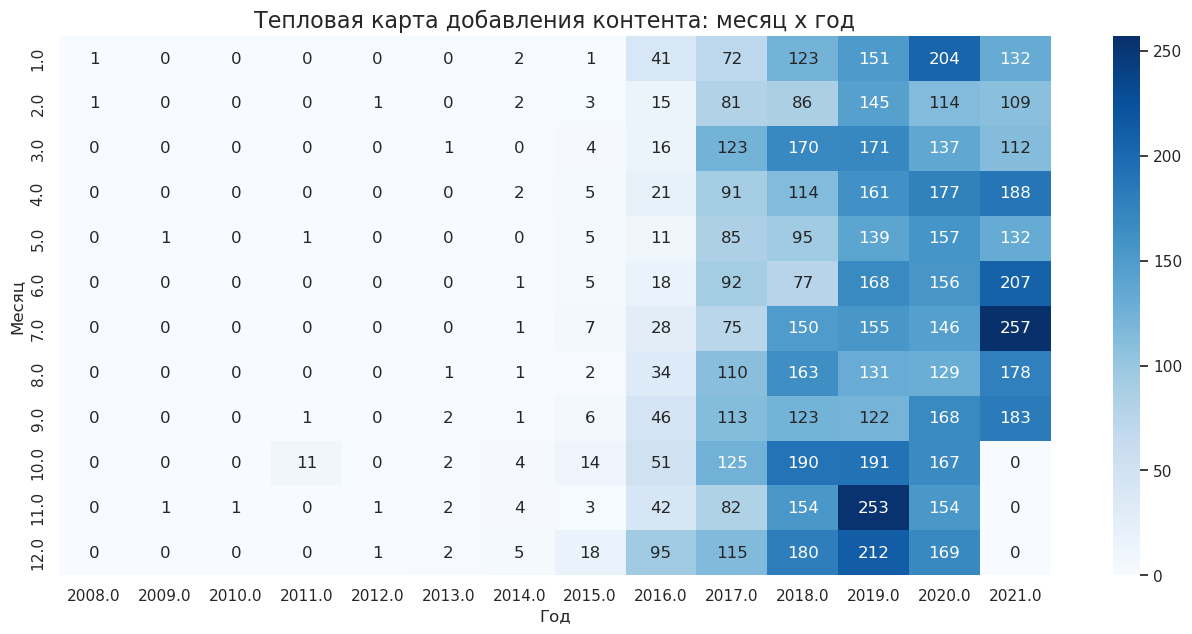

In [41]:
heatmap_data = df_clean.pivot_table(
    index='month_added',
    columns='year_added',
    values='show_id',
    aggfunc='count',
    fill_value=0
)

plt.figure(figsize=(16, 7))
sns.heatmap(heatmap_data, cmap='Blues', annot=True, fmt='g')
plt.title('Тепловая карта добавления контента: месяц x год')
plt.xlabel('Год')
plt.ylabel('Месяц')
plt.show()

# 21. Корреляция числовых признаков

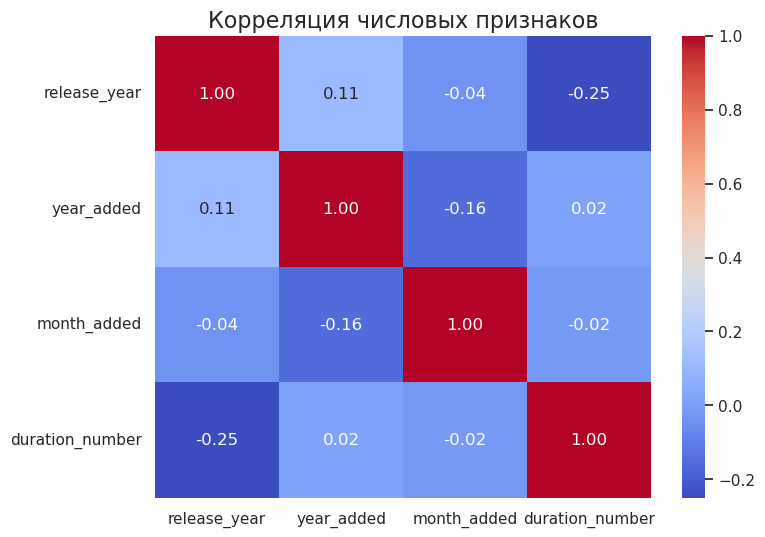

In [42]:
numeric_df = df_clean[['release_year', 'year_added', 'month_added', 'duration_number']].copy()

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляция числовых признаков')
plt.show()

# 22 Гипотеза о том, что фильмы с рейтингом TV-MA в среднем длиннее фильмов с рейтингом PG-13.
H0:
Средняя длительность фильмов TV-MA и PG-13 одинакова.

H1:
Средняя длительность фильмов TV-MA отличается от PG-13.

## Смотрим две средние

In [43]:
movies = df_clean[df_clean['type'] == 'Movie'].copy()

movies = movies[movies['duration_unit'] == 'minutes']

movies['duration_number'] = pd.to_numeric(
    movies['duration_number'],
    errors='coerce'
)

tv_ma = movies[movies['rating'] == 'TV-MA']['duration_number'].dropna()

pg13 = movies[movies['rating'] == 'PG-13']['duration_number'].dropna()

print('TV-MA mean:', tv_ma.mean())
print('PG-13 mean:', pg13.mean())

TV-MA mean: 95.88991270611058
PG-13 mean: 108.33061224489796


## Визуализация

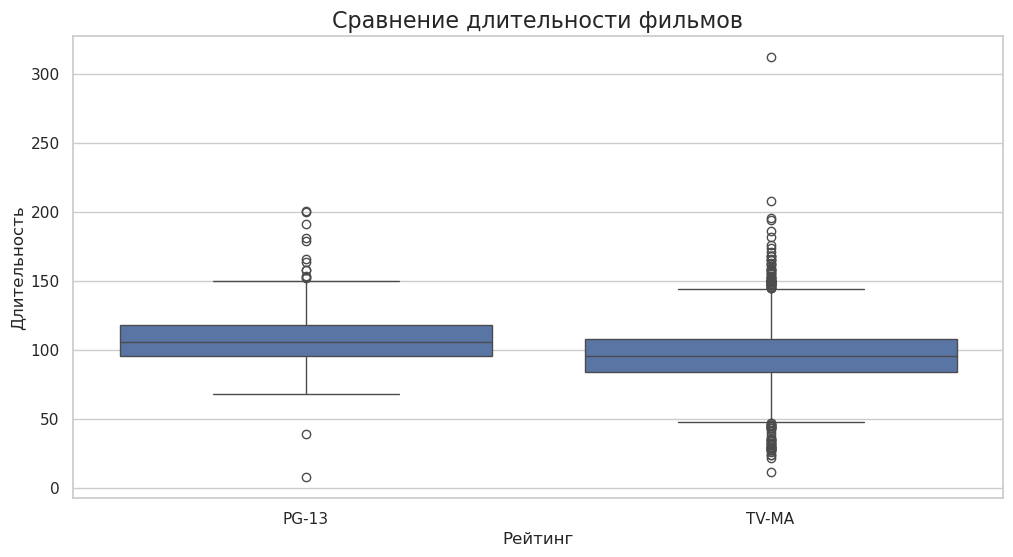

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    data=movies[
        movies['rating'].isin(['TV-MA', 'PG-13'])
    ],
    x='rating',
    y='duration_number'
)

plt.title('Сравнение длительности фильмов')
plt.xlabel('Рейтинг')
plt.ylabel('Длительность')
plt.show()

## Статистический тест

In [45]:
from scipy.stats import ttest_ind

stat, p_value = ttest_ind(tv_ma, pg13, equal_var=False)

print('t-statistic:', stat)
print('p-value:', p_value)

t-statistic: -12.238453928124583
p-value: 6.011398872233148e-32


Вывод: Средняя длительность фильмов TV-MA статистически отличается от PG-13.